In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
from IPython.display import Image, display

from data_analysis.config import load_config


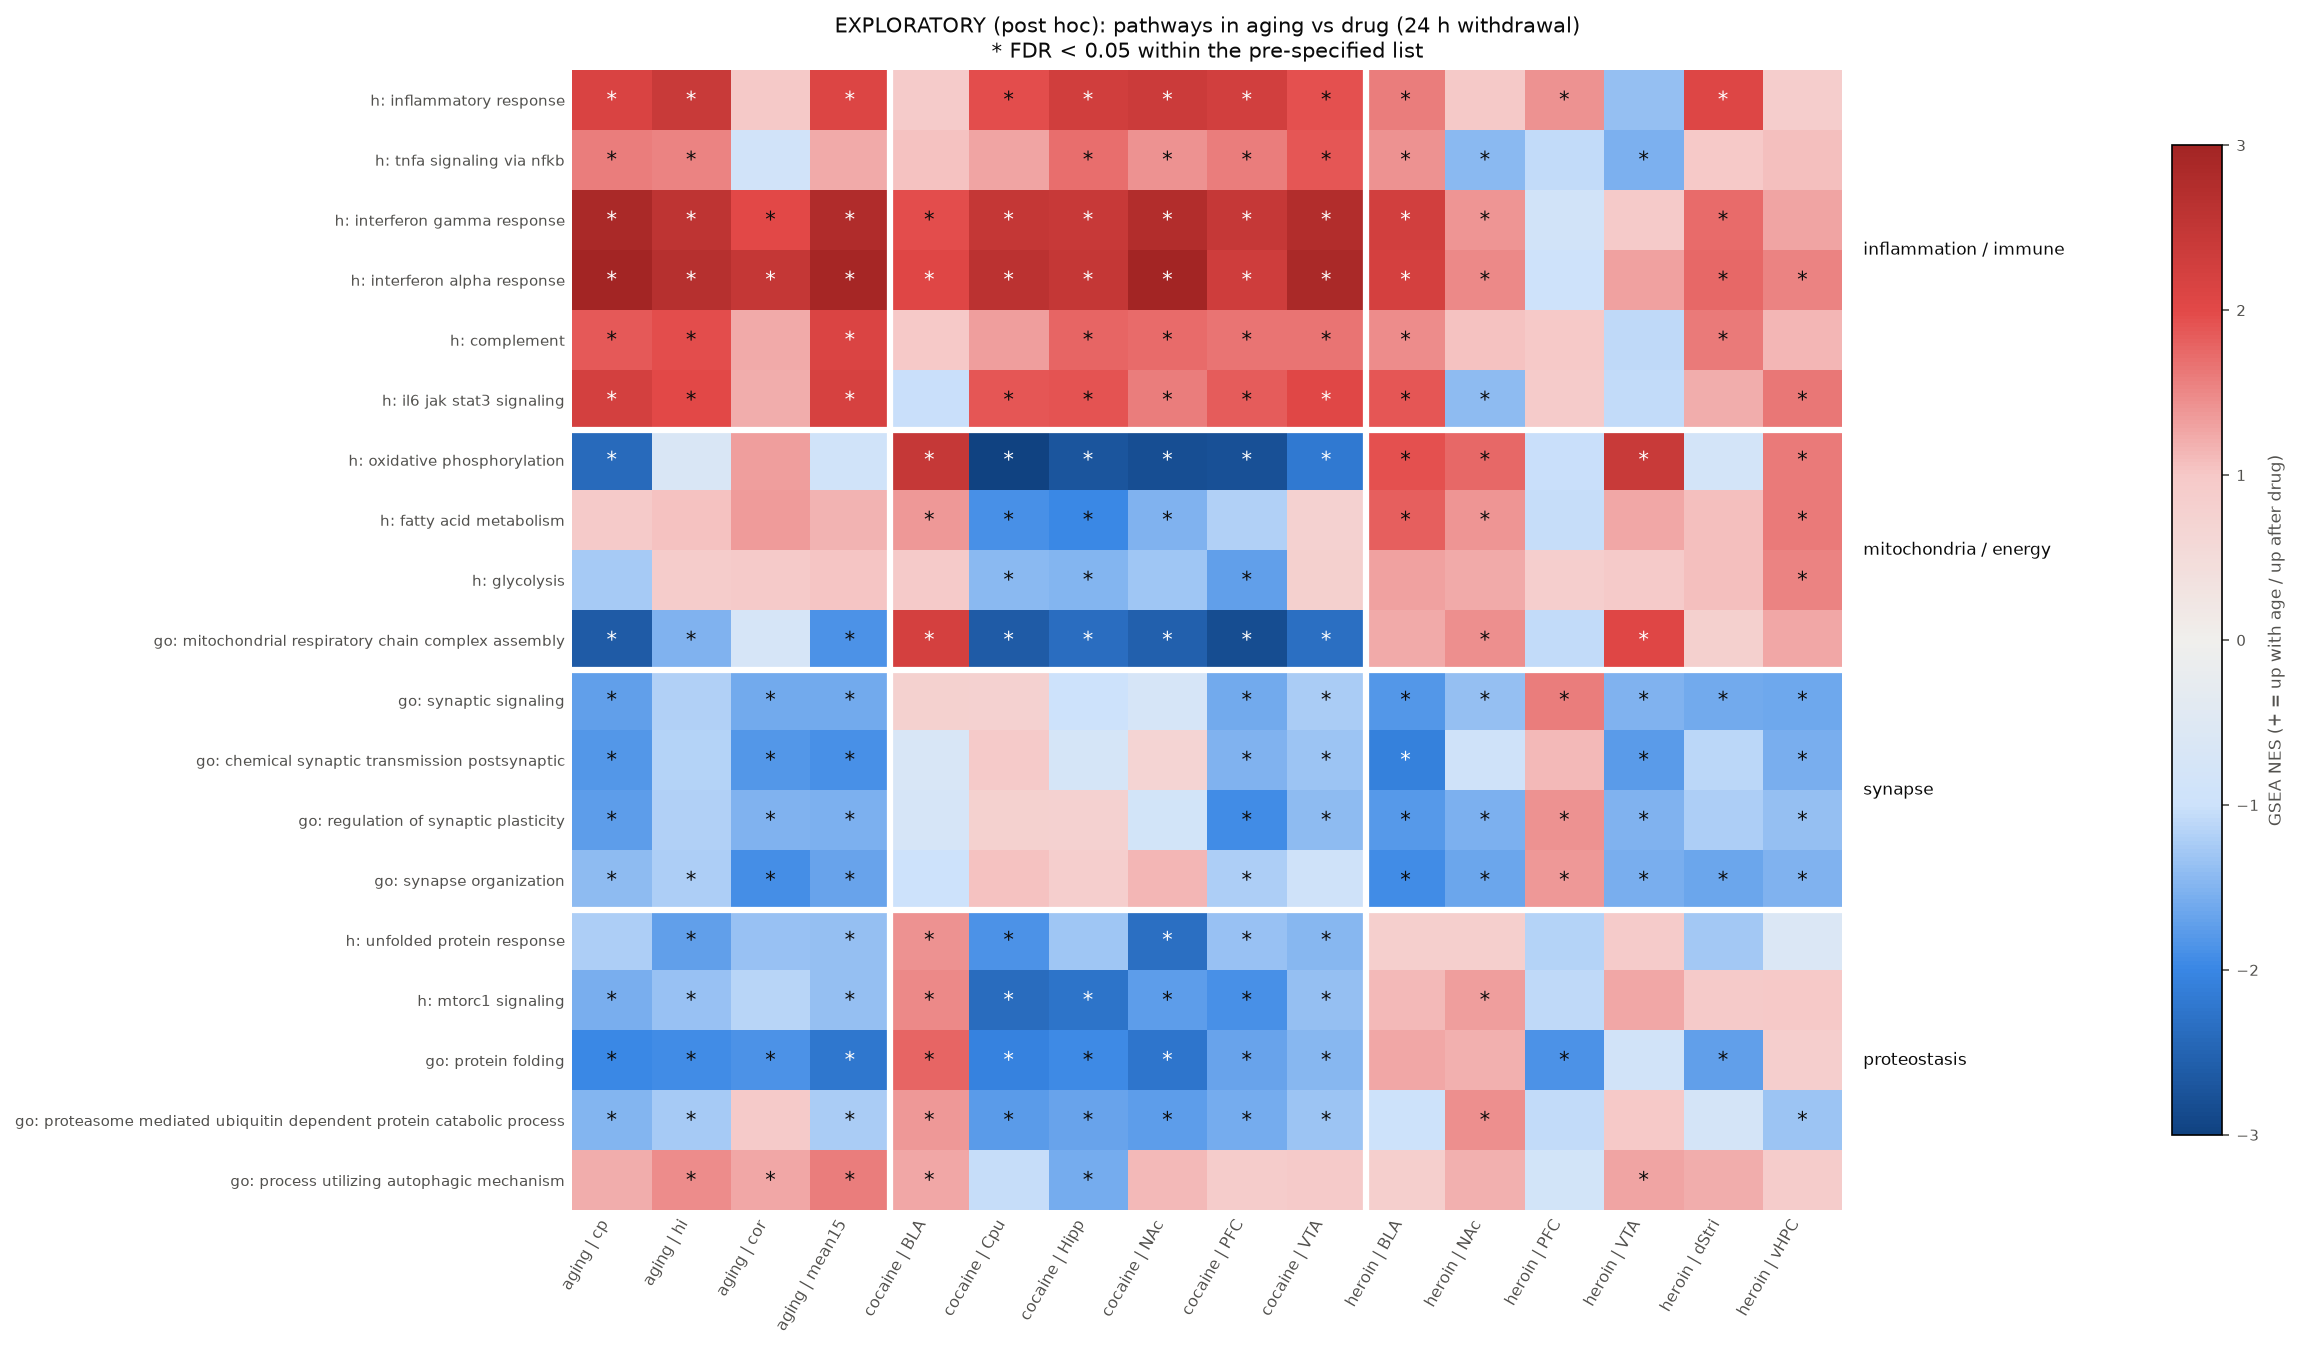

In [3]:
cfg = load_config()
tables, figs = cfg["paths"]["tables"], cfg["paths"]["figures"]
aging = pd.read_csv(tables / "table_pathway_aging_nes.csv")
drug = pd.read_csv(tables / "table_pathway_drug_nes.csv")
overlap = pd.read_csv(tables / "table_pathway_overlap.csv")
display(Image(figs / "fig_pathway_overlap.png"))

In [4]:
aging[aging["prespecified"]].pivot(index="pathway", columns="aging_ref", values="nes").round(2)

aging_ref,cor,cp,hi,mean15
pathway,,,,
GOBP_CHEMICAL_SYNAPTIC_TRANSMISSION_POSTSYNAPTIC,-1.81,-1.81,-1.17,-1.89
GOBP_MITOCHONDRIAL_RESPIRATORY_CHAIN_COMPLEX_ASSEMBLY,-0.73,-2.61,-1.50,-1.86
GOBP_PROCESS_UTILIZING_AUTOPHAGIC_MECHANISM,1.26,1.20,1.47,1.57
GOBP_PROTEASOME_MEDIATED_UBIQUITIN_DEPENDENT_PROTEIN_CATABOLIC_PROCESS,0.95,-1.50,-1.26,-1.22
GOBP_PROTEIN_FOLDING,-1.87,-1.99,-1.92,-2.22
GOBP_REGULATION_OF_SYNAPTIC_PLASTICITY,-1.52,-1.75,-1.19,-1.55
GOBP_SYNAPSE_ORGANIZATION,-1.91,-1.41,-1.22,-1.69
GOBP_SYNAPTIC_SIGNALING,-1.61,-1.73,-1.19,-1.60
HALLMARK_COMPLEMENT,1.23,1.86,1.96,2.12


In [5]:
overlap.pivot_table(index=["drug", "category"], columns="design", values="frac_same_direction").round(2)

design                         24 h withdrawal  30 d + context  \
drug    category                                                 
cocaine inflammation / immune             0.94            0.64   
        mitochondria / energy             0.58            0.58   
        proteostasis                      0.77            0.40   
        synapse                           0.62            0.62   
heroin  inflammation / immune             0.78            0.33   
        mitochondria / energy             0.50            0.50   
        proteostasis                      0.50            0.47   
        synapse                           0.83            0.79   

design                         30 d + drug (relapse)  first acute exposure  
drug    category                                                            
cocaine inflammation / immune                   0.86                  0.72  
        mitochondria / energy                   0.50                  0.42  
        proteostasis                            0.30                  0.70  
        synapse                                 0.75                  0.62  
heroin  inflammation / immune                   0.36                  0.19  
        mitochondria / energy                   0.46                  0.38  
        proteostasis                            0.30                  0.20  
        synapse                                 0.38                  0.50

In [6]:
hc = pd.read_csv(tables / "table_pathway_hallmark_correlation.csv")
hc.groupby(["drug", "design"])["spearman_rho_nes"].agg(["mean", "min", "max"]).round(2)

mean   min   max
drug    design                                 
cocaine 24 h withdrawal        0.39 -0.03  0.68
        30 d + context         0.18 -0.42  0.75
        30 d + drug (relapse)  0.20 -0.17  0.55
        first acute exposure   0.28 -0.19  0.56
heroin  24 h withdrawal        0.30 -0.06  0.71
        30 d + context         0.05 -0.14  0.55
        30 d + drug (relapse) -0.27 -0.63  0.41
        first acute exposure  -0.35 -0.50  0.04

In [7]:
p = "HALLMARK_OXIDATIVE_PHOSPHORYLATION"   # try a different pathway
drug.query("pathway == @p and design == '24 h withdrawal'")[["drug", "region", "nes", "fdr_prespecified"]].round(3)

,drug,region,nes,fdr_prespecified
1,cocaine,BLA,2.448,0.000
233,cocaine,Cpu,-3.075,0.000
464,cocaine,Hipp,-2.708,0.000
698,cocaine,NAc,-2.795,0.000
929,cocaine,PFC,-2.769,0.000
1165,cocaine,VTA,-2.197,0.000
1401,heroin,BLA,1.940,0.000
1626,heroin,NAc,1.741,0.000
1886,heroin,PFC,-1.027,0.538
2088,heroin,VTA,2.395,0.000


In [8]:
pd.read_csv(tables / "table_pathway_list.csv")

,category,pathway,n_genes_in_set,replaces
0,inflammation / immune,HALLMARK_INFLAMMATORY_RESPONSE,197,NaN
1,inflammation / immune,HALLMARK_TNFA_SIGNALING_VIA_NFKB,196,NaN
2,inflammation / immune,HALLMARK_INTERFERON_GAMMA_RESPONSE,188,NaN
3,inflammation / immune,HALLMARK_INTERFERON_ALPHA_RESPONSE,94,NaN
4,inflammation / immune,HALLMARK_COMPLEMENT,185,NaN
5,inflammation / immune,HALLMARK_IL6_JAK_STAT3_SIGNALING,85,NaN
6,mitochondria / energy,HALLMARK_OXIDATIVE_PHOSPHORYLATION,195,NaN
7,mitochondria / energy,HALLMARK_FATTY_ACID_METABOLISM,155,NaN
8,mitochondria / energy,HALLMARK_GLYCOLYSIS,200,NaN
9,mitochondria / energy,GOBP_MITOCHONDRIAL_RESPIRATORY_CHAIN_COMPLEX_A...,122,NaN
